# Chapitre 12 - Cours 1 : intégration de données

Le dernier chapitre du livre, *The Future of Data Systems*, change de ton : après avoir décrit l'existant, l'auteur propose sa vision de la manière dont les systèmes de données devraient être conçus, en s'appuyant surtout sur les flux d'événements du chapitre précédent. Le chapitre est plus engagé que les autres : il défend une approche plutôt qu'il n'en compare plusieurs.
Ce premier notebook couvre la section *Data Integration* : comment faire cohabiter
plusieurs outils spécialisés qui contiennent **les mêmes données sous des formes
différentes**, sans qu'ils finissent par se contredire.

**Plan.**

1. Combiner des outils spécialisés en dérivant des données.
2. Raisonner sur les flux : un seul ordre pour toutes les écritures.
3. Données dérivées contre transactions distribuées.
4. Les limites de l'ordre total.
5. Ordonner les événements pour capturer la causalité.
6. Maintenir un état dérivé et retraiter les données.
7. L'architecture lambda, et unifier traitements par lots et flux.

In [1]:
import math
import random

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import dataflow as dfl
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET, COLORS,
                           annotate_bars, finish, set_style, subtitle)
from ddia.timelines import SpaceTime

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
SHARDS = "partitions"   # vocabulaire de l'édition

## 1. Combiner des outils spécialisés en dérivant des données (section *Combining Specialized Tools by Deriving Data*)

Le fil rouge du livre est qu'il n'existe **pas de solution unique** : pour stocker puis
retrouver des données, on a vu des journaux et LSM-trees, des B-trees, du stockage en
colonnes (chapitre 3) ; pour répliquer, un leader, plusieurs, ou aucun
(chapitre 5). Un logiciel donné choisit **une** approche et l'optimise ;
même une base dite « généraliste » est conçue pour un certain profil d'usage. Une
application réelle a plusieurs profils d'usage, donc finit par **combiner plusieurs
outils**.

L'exemple canonique : une base transactionnelle (OLTP) pour les écritures et la vérité,
plus un **index de recherche plein texte** pour les requêtes par mots-clés. Certaines
bases (PostgreSQL) savent faire de la recherche plein texte simple, mais un vrai moteur
de recherche fait mieux ; à l'inverse, un index de recherche est un mauvais système de
référence durable. Et la liste s'allonge vite : entrepôt de données, caches et vues
dénormalisées, modèles d'apprentissage et de recommandation, notifications...

Le livre propose de penser ce paysage comme un **graphe de dérivation** : un seul
**système de référence** (system of record) reçoit les écritures, et chaque autre
représentation est une **donnée dérivée**, recalculable à partir de lui (distinction posée dans l'introduction de la partie III du livre).

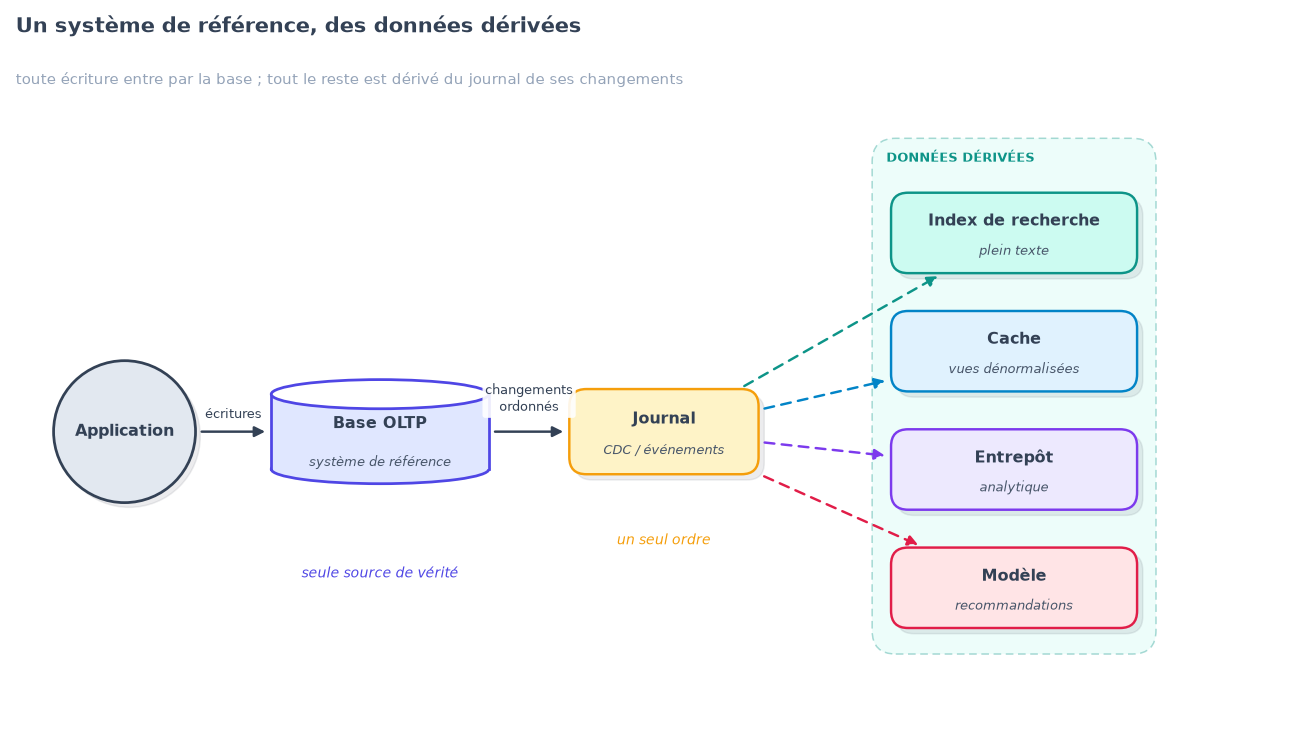

In [2]:
d = Diagram(13.5, 6.6, title="Un système de référence, des données dérivées",
            subtitle="toute écriture entre par la base ; tout le reste est dérivé du journal de ses changements")
d.box("app", 1.2, 3.1, "Application", kind="user", w=1.5, color=SLATE)
d.box("db", 3.9, 3.1, "Base OLTP", sub="système de référence", kind="db", color=INDIGO, w=2.3, h=1.1)
d.box("log", 6.9, 3.1, "Journal", sub="CDC / événements", color=AMBER, w=2.0, h=0.9)
targets = [("idx", "Index de recherche", "plein texte", TEAL, 5.2),
           ("cache", "Cache", "vues dénormalisées", SKY, 3.95),
           ("dwh", "Entrepôt", "analytique", VIOLET, 2.7),
           ("ml", "Modèle", "recommandations", ROSE, 1.45)]
for name, txt, sub, c, y in targets:
    d.box(name, 10.6, y, txt, sub=sub, color=c, w=2.6, h=0.85)
    d.arrow("log", name, style="dashed", color=c)
d.arrow("app", "db", "écritures")
d.arrow("db", "log", "changements\nordonnés", label_offset=(0, 0.35))
d.group(9.1, 0.75, 12.1, 6.2, "données dérivées", color=TEAL)
d.note(3.9, 1.6, "seule source de vérité", color=INDIGO)
d.note(6.9, 1.95, "un seul ordre", color=AMBER)
d.show()

**Pourquoi un journal central plutôt que des connexions point à point ?** Sans
discipline, chaque nouveau système est relié à plusieurs autres par des scripts de
synchronisation ad hoc. Avec $n$ systèmes, il peut y avoir jusqu'à $n(n-1)/2$
intégrations à écrire, tester et surveiller ; avec un journal central, chaque système
n'a qu'**un** connecteur (il publie ou consomme).

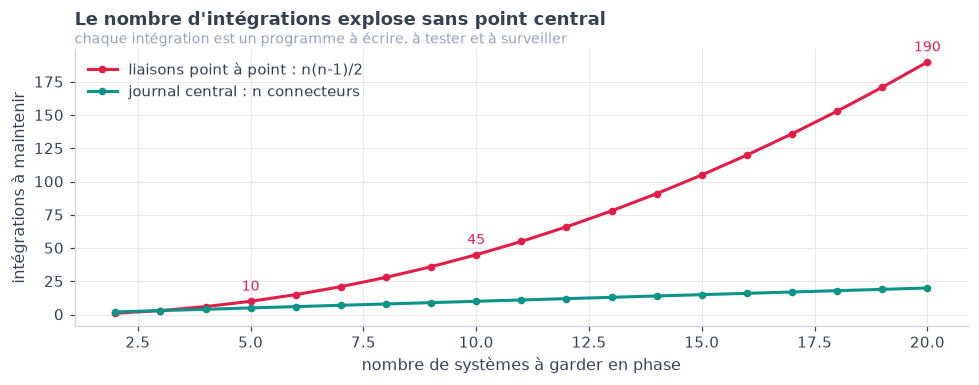

In [3]:
n = np.arange(2, 21)
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(n, n * (n - 1) / 2, color=ROSE, marker="o", ms=4, label="liaisons point à point : n(n-1)/2")
ax.plot(n, n, color=TEAL, marker="o", ms=4, label="journal central : n connecteurs")
for k in (5, 10, 20):
    ax.annotate(f"{k * (k - 1) // 2}", (k, k * (k - 1) / 2), (0, 7), textcoords="offset points",
                ha="center", fontsize=9, color=ROSE)
ax.set_xlabel("nombre de systèmes à garder en phase"); ax.set_ylabel("intégrations à maintenir")
ax.set_title("Le nombre d'intégrations explose sans point central")
subtitle(ax, "chaque intégration est un programme à écrire, à tester et à surveiller")
ax.legend(); plt.tight_layout(); plt.show()

> **À retenir.** Aucun outil ne sert bien tous les profils d'accès : on en combine
> plusieurs. Pour garder la maîtrise, on désigne **un** système de référence et on
> considère tout le reste comme des **données dérivées**, alimentées par un flux de
> changements.